# EDA 2 — Beijing PM2.5 (UCI 381)
**Nguồn:** https://archive.ics.uci.edu/dataset/381 · **License:** CC BY 4.0 · **Paper gốc:** Liang et al. (2015), *Assessing Beijing's PM2.5 pollution: severity, weather impact, APEC and winter heating*, Proc. Royal Society A 471:20150257, DOI 10.1098/rspa.2015.0257.

Nồng độ PM2.5 theo giờ tại Đại sứ quán Mỹ ở Bắc Kinh, 2010–2014, kèm khí tượng (DEWP điểm sương, TEMP, PRES, cbwd hướng gió, Iws tốc độ gió cộng dồn, Is/Ir số giờ tuyết/mưa cộng dồn). Mục tiêu: `pm2.5`.

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from eda_utils import *
warnings.filterwarnings('ignore'); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
plt.rcParams['figure.dpi'] = 80
RAW = ROOT / 'data' / 'raw'
SUMMARY = {}  # các số chính, lưu ra reports/ để notebook so sánh dùng lại

## 1. Đọc dữ liệu, shape, kiểu

In [2]:
df = pd.read_csv(RAW/'PRSA_data_2010.1.1-2014.12.31.csv')
df['t'] = pd.to_datetime(df[['year','month','day','hour']]); df = df.rename(columns={'pm2.5':'pm25'})
print('shape:', df.shape); display(df.head(3)); display(overview(df))
SUMMARY.update(dataset='pm25', rows=len(df), cols=df.shape[1]-1, freq='giờ', n_series=1)

shape: (43824, 14)


,No,year,month,day,hour,pm25,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir,t
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0,2010-01-01 00:00:00
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0,2010-01-01 01:00:00
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0,2010-01-01 02:00:00


,dtype,n_missing,pct_missing,n_unique
No,int64,0,0.000,43824
year,int64,0,0.000,5
month,int64,0,0.000,12
day,int64,0,0.000,31
hour,int64,0,0.000,24
pm25,float64,2067,4.717,581
DEWP,int64,0,0.000,69
TEMP,float64,0,0.000,64
PRES,float64,0,0.000,60
cbwd,str,0,0.000,4


## 2. Khoảng thời gian, giá trị thiếu, trùng lặp

In [3]:
g, missing = time_gaps(df['t'], 'h'); display(pd.Series(g))
na = df.pm25.isna(); runs = na.ne(na.shift()).cumsum()[na].value_counts()
print(f'pm25 thiếu: {na.sum()} ({na.mean()*100:.2f}%) | số đoạn thiếu liên tiếp: {len(runs)} | đoạn dài nhất: {runs.max()} giờ')
print('Phân bố độ dài đoạn thiếu:'); display(runs.describe().round(1))
print('Thiếu theo năm:', df[na].year.value_counts().sort_index().to_dict())
SUMMARY.update(start=g['start'], end=g['end'], missing_steps=g['n_missing_steps'], dup_ts=g['n_duplicated_ts'], n_na=int(na.sum()))

start              2010-01-01 00:00:00
end                2014-12-31 23:00:00
n_expected                       43824
n_unique                         43824
n_missing_steps                      0
n_duplicated_ts                      0
dtype: object

pm25 thiếu: 2067 (4.72%) | số đoạn thiếu liên tiếp: 214 | đoạn dài nhất: 155 giờ
Phân bố độ dài đoạn thiếu:


count    214.0
mean       9.7
std       21.4
min        1.0
25%        1.0
50%        1.0
75%        7.0
max      155.0
Name: count, dtype: float64

Thiếu theo năm: {2010: 669, 2011: 728, 2012: 489, 2013: 82, 2014: 99}


In [4]:
print(f"Nhận xét: lưới giờ đầy đủ ({g['n_missing_steps']} giờ thiếu, {g['n_duplicated_ts']} trùng) nhưng mục tiêu pm25 thiếu {na.sum()} giá trị ({na.mean()*100:.2f}%), "
      f"chia thành {len(runs)} đoạn, dài nhất {runs.max()} giờ, trung vị {runs.median():.0f} giờ. Đoạn ngắn có thể nội suy; đoạn dài nên che (mask) khi tính loss/đánh giá thay vì nội suy. "
      f"Năm 2010 có {int((df[na].year==2010).sum())} giá trị thiếu, 24 giờ đầu toàn NA: {df.pm25.iloc[:24].isna().all()}.")

Nhận xét: lưới giờ đầy đủ (0 giờ thiếu, 0 trùng) nhưng mục tiêu pm25 thiếu 2067 giá trị (4.72%), chia thành 214 đoạn, dài nhất 155 giờ, trung vị 1 giờ. Đoạn ngắn có thể nội suy; đoạn dài nên che (mask) khi tính loss/đánh giá thay vì nội suy. Năm 2010 có 669 giá trị thiếu, 24 giờ đầu toàn NA: True.


## 3. Thống kê mô tả, phân phối, độ lệch

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
pm25,41757.0,98.613,92.050,0.00,29.00,72.00,137.00,994.0,1.802,4.769
DEWP,43824.0,1.817,14.433,-40.00,-10.00,2.00,15.00,28.0,-0.152,-1.195
TEMP,43824.0,12.449,12.199,-19.00,2.00,14.00,23.00,42.0,-0.163,-1.111
PRES,43824.0,1016.448,10.269,991.00,1008.00,1016.00,1025.00,1046.0,0.098,-0.846
Iws,43824.0,23.889,50.011,0.45,1.79,5.37,21.91,585.6,4.298,23.421
Is,43824.0,0.053,0.760,0.00,0.00,0.00,0.00,27.0,19.484,449.082
Ir,43824.0,0.195,1.416,0.00,0.00,0.00,0.00,36.0,11.662,174.425


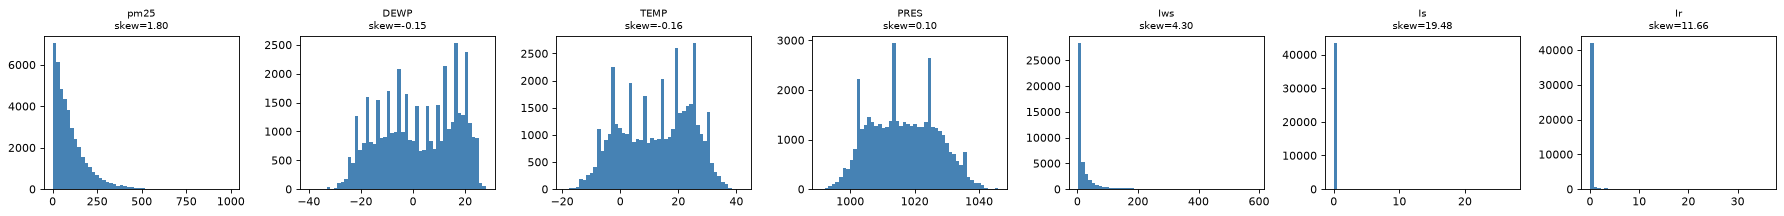

cbwd
SE    15290
NW    14150
cv     9387
NE     4997
Name: count, dtype: int64

skew log1p(pm25): -0.304 | % giờ Is>0: 0.84 | % giờ Ir>0: 4.13


In [5]:
num = ['pm25','DEWP','TEMP','PRES','Iws','Is','Ir']
st = shape_stats(df[num]); display(st); plot_dists(df, num)
display(df.cbwd.value_counts())
SUMMARY.update(target_mean=st.loc['pm25','mean'], target_skew=st.loc['pm25','skew'], target_kurt=st.loc['pm25','kurtosis'], target_cv=round(st.loc['pm25','std']/st.loc['pm25','mean'],3))
print('skew log1p(pm25):', round(np.log1p(df.pm25).skew(),3), '| % giờ Is>0:', round((df.Is>0).mean()*100,2), '| % giờ Ir>0:', round((df.Ir>0).mean()*100,2))

In [6]:
print(f"Nhận xét: pm25 TB {st.loc['pm25','mean']:.1f}, trung vị {st.loc['pm25','50%']:.0f}, max {st.loc['pm25','max']:.0f} µg/m³; "
      f"skew={st.loc['pm25','skew']:.2f}, kurtosis={st.loc['pm25','kurtosis']:.2f} → lệch phải nặng; log1p cho skew {np.log1p(df.pm25).skew():.2f}. "
      f"Iws skew={st.loc['Iws','skew']:.2f}; Is/Ir gần như toàn 0 (Is>0 {(df.Is>0).mean()*100:.2f}%, Ir>0 {(df.Ir>0).mean()*100:.2f}% số giờ) → biến thưa.")

Nhận xét: pm25 TB 98.6, trung vị 72, max 994 µg/m³; skew=1.80, kurtosis=4.77 → lệch phải nặng; log1p cho skew -0.30. Iws skew=4.30; Is/Ir gần như toàn 0 (Is>0 0.84%, Ir>0 4.13% số giờ) → biến thưa.


## 4. Outlier (IQR 1.5)

In [7]:
out = iqr_outliers(df[num]); display(out); SUMMARY['target_outlier_pct'] = out.loc['pm25','pct']
print(f"Nhận xét: {int(out.loc['pm25','n_outliers'])} giờ ({out.loc['pm25','pct']}%) pm25 > {out.loc['pm25','upper']:.0f}; đây là các đợt ô nhiễm thật (giá trị quan trọng nhất cần dự báo) → không xoá; dùng log hoặc loss bền vững.")

,lower,upper,n_outliers,pct
pm25,-133.00,299.00,1773.0,4.246
DEWP,-47.50,52.50,0.0,0.000
TEMP,-29.50,54.50,0.0,0.000
PRES,982.50,1050.50,0.0,0.000
Iws,-28.39,52.09,5101.0,11.640
Is,0.00,0.00,368.0,0.840
Ir,0.00,0.00,1808.0,4.126


Nhận xét: 1773 giờ (4.246%) pm25 > 299; đây là các đợt ô nhiễm thật (giá trị quan trọng nhất cần dự báo) → không xoá; dùng log hoặc loss bền vững.


## 5. Xu hướng & mùa vụ

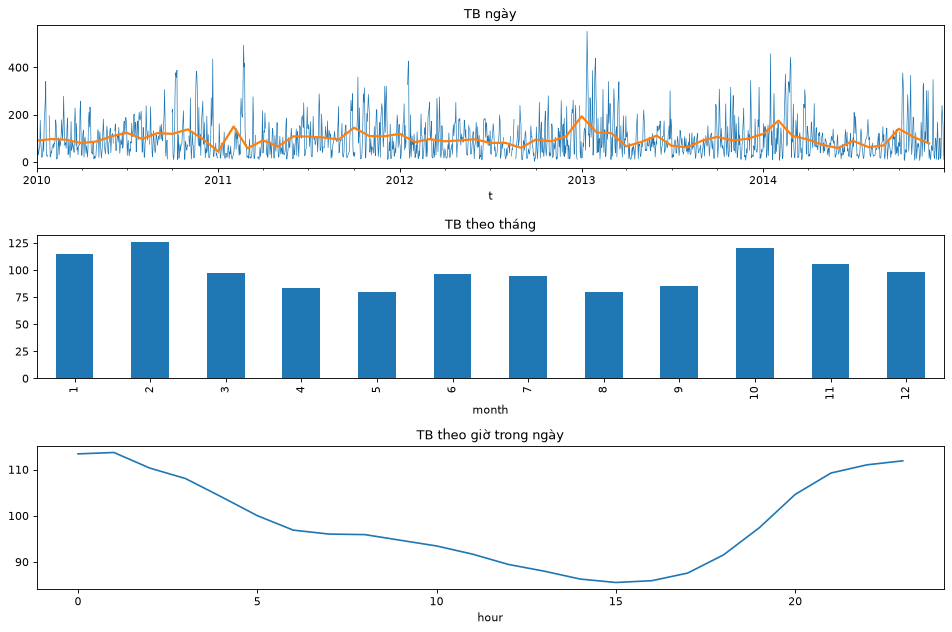

TB theo năm: {2010: 104.0, 2011: 99.1, 2012: 90.5, 2013: 101.7, 2014: 97.7}


In [8]:
s = df.set_index('t')['pm25']
fig, ax = plt.subplots(3,1, figsize=(12,8))
s.resample('D').mean().plot(ax=ax[0], lw=.6, title='TB ngày'); s.resample('MS').mean().plot(ax=ax[0], lw=2)
df.groupby('month').pm25.mean().plot.bar(ax=ax[1], title='TB theo tháng'); df.groupby('hour').pm25.mean().plot(ax=ax[2], title='TB theo giờ trong ngày')
plt.tight_layout(); plt.show()
yr = df.groupby('year').pm25.mean().round(1); mo = df.groupby('month').pm25.mean(); hr = df.groupby('hour').pm25.mean()
print('TB theo năm:', yr.to_dict())

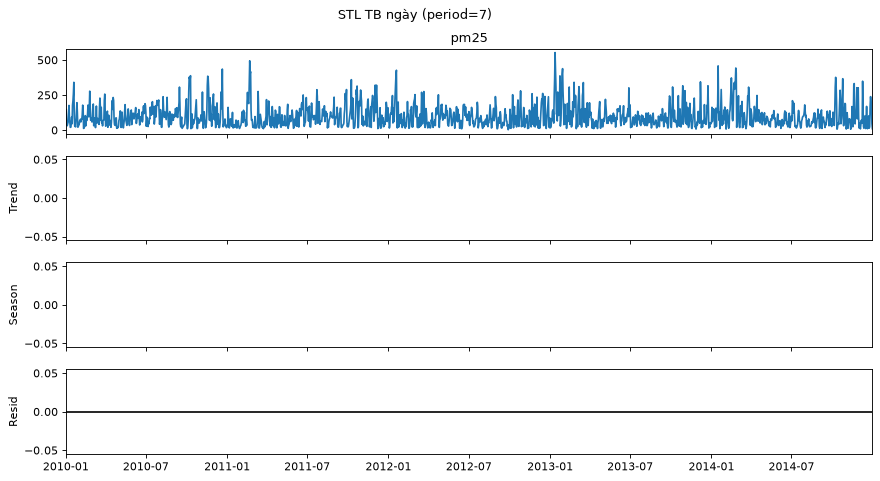

STL ngày (period 7): {'trend_strength': 0, 'seasonal_strength': 0} | STL giờ (period 24): {'trend_strength': np.float64(0.867), 'seasonal_strength': np.float64(0.411)}


In [9]:
sd = s.resample('D').mean().interpolate()
sw = stl_strength(sd, period=7, title='STL TB ngày (period=7)')
sh = s.interpolate(limit_direction='both')
sday = stl_strength(sh, period=24, plot=False)
print('STL ngày (period 7):', sw, '| STL giờ (period 24):', sday)
SUMMARY.update(trend_strength=sw['trend_strength'], seasonal_strength=sday['seasonal_strength'])

In [10]:
print(f"Nhận xét: TB theo năm {yr.to_dict()} → không có xu hướng đơn điệu mạnh. Tháng cao nhất {mo.idxmax()} ({mo.max():.0f}), thấp nhất {mo.idxmin()} ({mo.min():.0f}) → mùa đông (sưởi) ô nhiễm hơn. "
      f"Theo giờ: cao nhất {hr.idxmax()}h ({hr.max():.0f}), thấp nhất {hr.idxmin()}h ({hr.min():.0f}). Độ mạnh mùa ngày STL = {sday['seasonal_strength']} (mức vừa); STL chuỗi ngày period 7 = {sw} → gần như không có mùa vụ tuần, biến động chủ yếu theo đợt thời tiết.")

Nhận xét: TB theo năm {2010: 104.0, 2011: 99.1, 2012: 90.5, 2013: 101.7, 2014: 97.7} → không có xu hướng đơn điệu mạnh. Tháng cao nhất 2 (126), thấp nhất 8 (80) → mùa đông (sưởi) ô nhiễm hơn. Theo giờ: cao nhất 1h (114), thấp nhất 15h (86). Độ mạnh mùa ngày STL = 0.411 (mức vừa); STL chuỗi ngày period 7 = {'trend_strength': 0, 'seasonal_strength': 0} → gần như không có mùa vụ tuần, biến động chủ yếu theo đợt thời tiết.


## 6. ACF/PACF

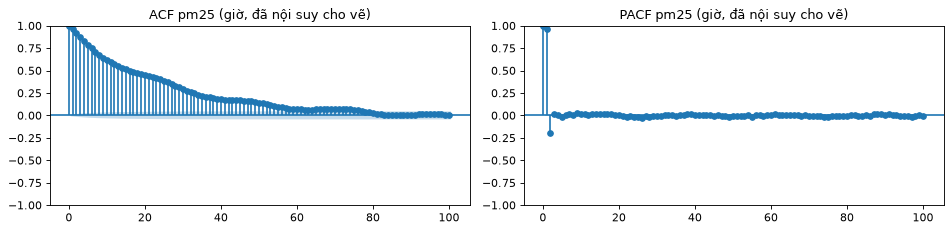

{'lag1': np.float64(0.965), 'lag2': np.float64(0.92), 'lag6': np.float64(0.747), 'lag24': np.float64(0.398), 'lag168': np.float64(0.023)}
Nhận xét: lag1=0.965 rất cao nhưng giảm nhanh (lag24=0.398, lag168=0.023) → chuỗi có quán tính ngắn hạn, dự báo xa sẽ khó; PACF gợi ý vài lag đầu là chính.


In [11]:
acf_pacf(sh, lags=100, title='pm25 (giờ, đã nội suy cho vẽ)')
ac = autocorrs(s, [1,2,6,24,168]); print(ac); SUMMARY['acf'] = ac
print(f"Nhận xét: lag1={ac['lag1']} rất cao nhưng giảm nhanh (lag24={ac['lag24']}, lag168={ac['lag168']}) → chuỗi có quán tính ngắn hạn, dự báo xa sẽ khó; PACF gợi ý vài lag đầu là chính.")

## 7. Kiểm định dừng

In [12]:
res = pd.DataFrame([stationarity(s.dropna(), 'pm25 giờ (bỏ NA)'), stationarity(sd, 'pm25 TB ngày')]); display(res)
SUMMARY['stationarity'] = res.set_index('series')['kết luận'].to_dict()
print('Nhận xét:', '; '.join(f"{r.series}: ADF p={r.ADF_p}, KPSS p={r['KPSS_p(bị chặn 0.01-0.1)']} → {r['kết luận']}" for _, r in res.iterrows()))

,series,n,ADF_stat,ADF_p,KPSS_stat,KPSS_p(bị chặn 0.01-0.1),kết luận
0,pm25 giờ (bỏ NA),41757,-20.607,0.0,0.101,0.1,dừng
1,pm25 TB ngày,1825,-10.124,0.0,0.070,0.1,dừng


Nhận xét: pm25 giờ (bỏ NA): ADF p=0.0, KPSS p=0.1 → dừng; pm25 TB ngày: ADF p=0.0, KPSS p=0.1 → dừng


## 8. Tương quan với biến ngoại sinh

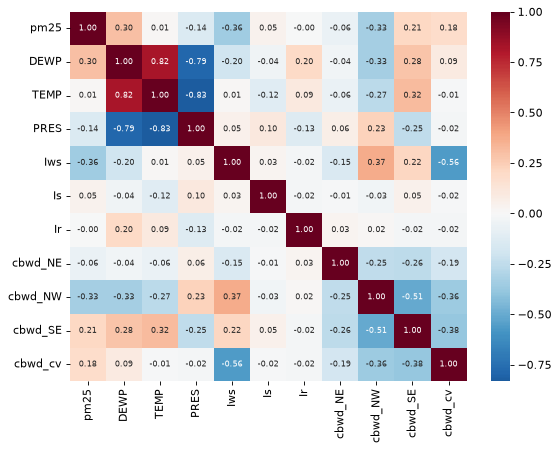

Iws       -0.360
cbwd_NW   -0.332
DEWP       0.300
cbwd_SE    0.211
cbwd_cv    0.181
PRES      -0.142
cbwd_NE   -0.061
Is         0.047
TEMP       0.011
Ir        -0.002
Name: pm25, dtype: float64

,mean,median,count
cbwd,,,
NE,90.2,55.0,4756
NW,70.1,31.0,13484
SE,110.8,91.0,14573
cv,126.2,98.0,8944


In [13]:
d2 = pd.get_dummies(df[['pm25','DEWP','TEMP','PRES','Iws','Is','Ir','cbwd']], columns=['cbwd'], dtype=float)
corr = d2.corr(method='spearman'); plt.figure(figsize=(8,6)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, annot_kws={'size':7}); plt.show()
c = corr['pm25'].drop('pm25').sort_values(key=abs, ascending=False); display(c.round(3))
display(df.groupby('cbwd').pm25.agg(['mean','median','count']).round(1))
SUMMARY['top_exog'] = c.round(3).head(3).to_dict()

In [14]:
bw = df.groupby('cbwd').pm25.mean()
print(f"Nhận xét: tương quan Spearman mạnh nhất với pm25: {', '.join(f'{k}={v:.2f}' for k,v in c.head(4).items())}. "
      f"Hướng gió quan trọng: TB pm25 khi gió {bw.idxmax()} là {bw.max():.0f}, khi gió {bw.idxmin()} là {bw.min():.0f}. Iws là tốc độ gió CỘNG DỒN (reset khi đổi hướng) → cân nhắc sai phân.")

Nhận xét: tương quan Spearman mạnh nhất với pm25: Iws=-0.36, cbwd_NW=-0.33, DEWP=0.30, cbwd_SE=0.21. Hướng gió quan trọng: TB pm25 khi gió cv là 126, khi gió NW là 70. Iws là tốc độ gió CỘNG DỒN (reset khi đổi hướng) → cân nhắc sai phân.


In [15]:
import json; (ROOT/'reports').mkdir(exist_ok=True)
json.dump(SUMMARY, open(ROOT/'reports'/f"summary_{SUMMARY['dataset']}.json", 'w'), ensure_ascii=False, indent=1, default=str)
SUMMARY

{'dataset': 'pm25',
 'rows': 43824,
 'cols': 13,
 'freq': 'giờ',
 'n_series': 1,
 'start': Timestamp('2010-01-01 00:00:00'),
 'end': Timestamp('2014-12-31 23:00:00'),
 'missing_steps': 0,
 'dup_ts': 0,
 'n_na': 2067,
 'target_mean': np.float64(98.613),
 'target_skew': np.float64(1.802),
 'target_kurt': np.float64(4.769),
 'target_cv': np.float64(0.933),
 'target_outlier_pct': np.float64(4.246),
 'trend_strength': 0,
 'seasonal_strength': np.float64(0.411),
 'acf': {'lag1': np.float64(0.965),
  'lag2': np.float64(0.92),
  'lag6': np.float64(0.747),
  'lag24': np.float64(0.398),
  'lag168': np.float64(0.023)},
 'stationarity': {'pm25 giờ (bỏ NA)': 'dừng', 'pm25 TB ngày': 'dừng'},
 'top_exog': {'Iws': -0.36, 'cbwd_NW': -0.332, 'DEWP': 0.3}}